# Projeto 2 — Q-learning e Sarsa no Taxi-v4

**Conceitos básicos de aprendizado por reforço e ambientes não determinísticos**

Este relatório resolve os itens 1 a 5 com Gymnasium. Compara cinco treinamentos
independentes de cada algoritmo no ambiente determinístico e na chuva, acompanha
o retorno de cada episódio e avalia as tabelas aprendidas em partidas novas.
Os resultados e a discussão abaixo são calculados a partir dos experimentos executados.

| Parte do enunciado | Evidência neste notebook |
|---|---|
| 1. Cinco treinamentos Q-learning e meta de reward | Histórico completo, curvas individuais e referência 8 |
| 2–3. Avaliação em 100 partidas e comparação com Sarsa | Resumo da execução 1, cinco execuções e gráfico conjunto |
| 4. Tabela seca aplicada na chuva | Teste seco → chuva, sem atualizar a tabela |
| 5. Treinamento na chuva | Cinco novos treinamentos de cada algoritmo e comparação |

Os módulos `taxi_rl.py` e `taxi_report.py` contêm a implementação reutilizada aqui.
Este notebook pode carregar os dados entregues ou refazer todos os treinamentos.

## 1. Ambiente, recompensas e meta

O Taxi-v4 possui **500 estados codificados** e **6 ações**: sul, norte, leste,
oeste, pegar e deixar passageiro. Há 300 estados iniciais possíveis. A recompensa
é −1 por passo comum, +20 pela entrega correta e −10 por tentativa ilegal de
pegar/deixar. O retorno de um episódio é a soma **não descontada** das recompensas;
o desconto γ é usado apenas na atualização dos valores Q.

Uma entrega em T passos, sem ações ilegais, tem retorno **21 − T**. Portanto,
+20 é a recompensa da entrega, não uma meta de retorno médio por episódio.
O registro oficial estabelece **reward_threshold = 8** para o Taxi-v4 padrão.
Usamos retorno médio ≥ 8 como referência operacional do ambiente seco, e não
como exigência para cada episódio ou certificado de política ótima.

Na chuva, `is_rainy=True, rainy_probability=0.6` significa 60% de probabilidade
de tentar a direção solicitada e 20% para cada lateral. Paredes ainda bloqueiam
movimentos; pegar e deixar continuam determinísticos. Não ativamos passageiro
volúvel. O limiar 8 continua no registro, mas não foi recalibrado para a chuva;
aparece nesse cenário apenas como referência do ambiente seco.

Preservamos o wrapper `TimeLimit` de **200 passos**. Não usamos `.env` para
remover wrappers nem `render_mode="human"` nos experimentos: renderização não
participa do aprendizado e tornaria as repetições mais lentas.

Fontes: [documentação oficial do Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/),
[registro do Taxi-v4 no Gymnasium 1.3.0](https://github.com/Farama-Foundation/Gymnasium/blob/v1.3.0/gymnasium/envs/__init__.py),
[tratamento de limites de tempo](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/).

In [1]:
from dataclasses import asdict
from pathlib import Path
import inspect
import json
import sys
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from taxi_rl import (
    Config, LABELS, make_env, train, evaluate, td_update, epsilon_greedy,
    run_experiments, load_results, demonstrate,
)
from taxi_report import save_figures, discussion

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
CONFIG = Config()
OUTPUT = Path("resultados")
print(f"Python {sys.version.split()[0]} | Gymnasium {gym.__version__}")
print(f"Ambiente: Taxi-v4 | meta seca: {gym.spec('Taxi-v4').reward_threshold}")

Python 3.13.13 | Gymnasium 1.3.0
Ambiente: Taxi-v4 | meta seca: 8


## 2. Protocolo experimental e hiperparâmetros

São **20 treinamentos**: 2 algoritmos × 2 ambientes × 5 sementes. Cada tabela
começa em zero e aprende por 20.000 episódios. O mesmo orçamento, as mesmas
sementes por execução e as mesmas regras de α e ε valem para todos os grupos.
As seis ações estão sempre disponíveis: não usamos `action_mask` nem conhecimento
prévio do mapa para escolher ações.

- **γ = 0,99:** considera o custo de trajetos longos.
- **α inicial = 0,6:** aprendizado rápido nas primeiras visitas; para a n-ésima
  visita a (s,a), αₙ = 0,6 / [1 + 0,01(n − 1)]⁰·⁶. A redução por visita diminui
  a influência de transições isoladas na chuva sem alterar o protocolo entre algoritmos.
- **ε-greedy:** εₑ = max(0,005; 1,0 × 0,9995ᵉ), com e começando em zero.
  Há exploração ampla no início e pouca exploração no final. Empates durante
  o treino são sorteados para não privilegiar a primeira ação.
- **Validação:** a cada 1.000 episódios, 100 partidas gulosas em ambiente separado;
  não atualizam Q nem mudam o sorteio do treino. Não há parada antecipada ou
  escolha de hiperparâmetros/tabelas a partir do teste.
- **Teste final:** ε = 0; 100 partidas por tabela e cenário, com desempate por
  menor índice. A **execução 1** é a representante definida antecipadamente;
  também mostramos todas as cinco para medir variabilidade. São 4.000 testes,
  incluindo chuva → seco como diagnóstico adicional.
- **Sementes separadas:** treino 2026–2030; teste 1.000.000–1.000.099;
  validação 2.000.000–2.000.099. Os métodos recebem os mesmos estados iniciais
  de teste; trajetórias podem divergir conforme suas ações.

Estes valores são uma escolha prática, não o resultado de uma busca exaustiva.
O primeiro checkpoint que alcança 8 indica velocidade de aprendizado no seco,
com resolução de 1.000 episódios; não comprova convergência permanente.

In [2]:
display(pd.DataFrame(asdict(CONFIG).items(), columns=["Hiperparâmetro", "Valor"]))

,Hiperparâmetro,Valor
0,episodes,20000.000
1,runs,5.000
2,evaluation_episodes,100.000
3,alpha,0.600
4,alpha_decay,0.010
5,alpha_power,0.600
6,gamma,0.990
7,epsilon_start,1.000
8,epsilon_min,0.005
9,epsilon_decay,1.000


## 3. Algoritmos e implementação

**Q-learning (off-policy):**

$$Q(s_t,a_t) \leftarrow Q(s_t,a_t) + \alpha\left[r_{t+1}
+ \gamma\max_a Q(s_{t+1},a) - Q(s_t,a_t)\right].$$

**Sarsa (on-policy):** primeiro sorteia a próxima ação pela política ε-greedy;
essa é a ação usada no alvo e executada no passo seguinte:

$$Q(s_t,a_t) \leftarrow Q(s_t,a_t) + \alpha\left[r_{t+1}
+ \gamma Q(s_{t+1},a_{t+1}) - Q(s_t,a_t)\right].$$

Em uma entrega (`terminated=True`), o alvo é somente a recompensa.
Um limite externo (`truncated=True`) encerra a coleta, mas mantém o bootstrap
do próximo estado. Tratar truncamento como estado terminal introduziria viés.
Abaixo estão as funções efetivamente usadas, carregadas do módulo para que
a explicação e a implementação permaneçam consistentes.

In [3]:
for function in (epsilon_greedy, td_update, train):
    display(Markdown(f"### `{function.__name__}`\n```python\n{inspect.getsource(function)}\n```"))

### `epsilon_greedy`
```python
def epsilon_greedy(q_row: np.ndarray, epsilon: float,
                   rng: np.random.Generator) -> int:
    if rng.random() < epsilon:
        return int(rng.integers(len(q_row)))
    # Empates são sorteados no treinamento, evitando favorecer a ação 0.
    best = np.flatnonzero(q_row == q_row.max())
    return int(best[rng.integers(len(best))])

```

### `td_update`
```python
def td_update(q_table, state, action, reward, next_state, terminated,
              algorithm, alpha, gamma, next_action=None):
    """Não anula o bootstrap em truncamento externo; só em terminação real."""
    if algorithm not in ALGORITHMS:
        raise ValueError(f"Algoritmo desconhecido: {algorithm}")
    target = float(reward)
    if not terminated:
        if algorithm == "q_learning":
            target += gamma * float(q_table[next_state].max())
        else:
            if next_action is None:
                raise ValueError("Sarsa precisa da próxima ação da política.")
            target += gamma * float(q_table[next_state, next_action])
    q_table[state, action] += alpha * (target - q_table[state, action])
    return target

```

### `train`
```python
def train(algorithm: str, scenario: str, config: Config, seed: int):
    """Treina uma tabela nova e retorna tabela, histórico e checkpoints."""
    if algorithm not in ALGORITHMS:
        raise ValueError(f"Algoritmo desconhecido: {algorithm}")
    env = make_env(scenario, config)
    rng = np.random.default_rng(seed)
    q_table = np.zeros((env.observation_space.n, env.action_space.n), dtype=np.float64)
    visits = np.zeros_like(q_table, dtype=np.int64)
    rows, checkpoints = [], []
    try:
        for episode in range(config.episodes):
            # O gerador do ambiente é independente do gerador da política.
            state, _ = env.reset(seed=seed if episode == 0 else None)
            epsilon = epsilon_at(episode, config)
            action = epsilon_greedy(q_table[state], epsilon, rng)
            total_reward = 0.0
            terminated = truncated = False
            for steps in range(1, config.max_steps + 1):
                next_state, reward, terminated, truncated, _ = env.step(action)
                # Sarsa escolhe uma vez e executa exatamente essa próxima ação.
                next_action = None
                if algorithm == "sarsa" and not terminated:
                    next_action = epsilon_greedy(q_table[next_state], epsilon, rng)
                visits[state, action] += 1
                alpha = config.alpha / (
                    1 + config.alpha_decay * (visits[state, action] - 1)
                ) ** config.alpha_power
                td_update(q_table, state, action, reward, next_state, terminated,
                          algorithm, alpha, config.gamma, next_action)
                total_reward += reward
                if terminated or truncated:
                    break
                state = next_state
                action = (next_action if algorithm == "sarsa" else
                          epsilon_greedy(q_table[state], epsilon, rng))
            rows.append({"episodio": episode + 1, "reward": total_reward,
                         "timesteps": steps, "epsilon": epsilon,
                         "sucesso": bool(terminated), "truncado": bool(truncated)})
            if (episode + 1) % config.checkpoint_every == 0 or episode + 1 == config.episodes:
                validation = evaluate(
                    q_table, scenario, config,
                    range(config.validation_seed,
                          config.validation_seed + config.validation_episodes),
                )
                checkpoints.append({
                    "episodio": episode + 1,
                    "reward_medio": validation.reward.mean(),
                    "timesteps_medios": validation.timesteps.mean(),
                    "taxa_sucesso": validation.sucesso.mean(),
                })
    finally:
        env.close()
    return q_table, pd.DataFrame(rows), pd.DataFrame(checkpoints)

```

## 4. Execução dos experimentos

Com `REFAZER_TREINAMENTOS = False`, os dados salvos são reutilizados após
conferir a configuração. Altere para `True` para refazer as vinte tabelas.
Se os resultados ainda não existirem, o notebook os calcula automaticamente.
Os arquivos CSV mantêm cada episódio de treinamento e cada partida de teste;
as tabelas Q são salvas como `.npy`.

In [4]:
REFAZER_TREINAMENTOS = False
if REFAZER_TREINAMENTOS or not (OUTPUT / "metadados.json").exists():
    resultados = run_experiments(CONFIG, OUTPUT)
else:
    metadata = json.loads((OUTPUT / "metadados.json").read_text(encoding="utf-8"))
    if metadata["config"] != asdict(CONFIG):
        raise ValueError("Configuração salva diferente. Ative REFAZER_TREINAMENTOS.")
    if metadata["gymnasium"] != gym.__version__:
        raise ValueError("Use a versão registrada do Gymnasium ou refaça o treinamento.")
    resultados = load_results(OUTPUT)

historico = resultados["treinamento"]
avaliacoes = resultados["avaliacoes"]
checkpoints = resultados["checkpoints"]
eficiencia = resultados["eficiencia_aprendizado"]
por_execucao = resultados["resumo_por_execucao"]
resumo = resultados["resumo_avaliacoes"]
print(f"{len(historico):,} episódios registrados; {len(avaliacoes):,} partidas de teste.")
print(f"Tabelas salvas: {len(list((OUTPUT / 'q_tables').glob('*.npy')))}")
display(historico.head())

400,000 episódios registrados; 4,000 partidas de teste.
Tabelas salvas: 20


,episodio,reward,timesteps,epsilon,sucesso,truncado,algoritmo,treino,execucao,seed_treino
0,1,-579.000,168,1.000,True,False,q_learning,deterministico,1,2026
1,2,-803.000,200,1.000,False,True,q_learning,deterministico,1,2026
2,3,-803.000,200,0.999,False,True,q_learning,deterministico,1,2026
3,4,-228.000,69,0.999,True,False,q_learning,deterministico,1,2026
4,5,-758.000,200,0.998,False,True,q_learning,deterministico,1,2026


## 5. Curvas de aprendizado — itens 1, 3 e 5

A figura principal reúne Q-learning e Sarsa; cada painel corresponde a um
ambiente. Para cada execução calculamos uma média móvel de 100 episódios e
então a média entre as cinco execuções. A faixa mostra **±1 desvio padrão
amostral entre as cinco curvas suavizadas**, não intervalo de confiança.
Os primeiros 99 episódios não aparecem na suavização, mas estão no CSV.

O eixo de reward usa **symlog**, linear entre −20 e +20 e logarítmico fora
dessa faixa, para mostrar tanto as penalidades iniciais quanto a aproximação
da meta. Essa transformação afeta apenas o desenho, não os dados ou as médias.
O retorno mostrado é o retorno por episódio, não sua soma ao longo do treinamento.

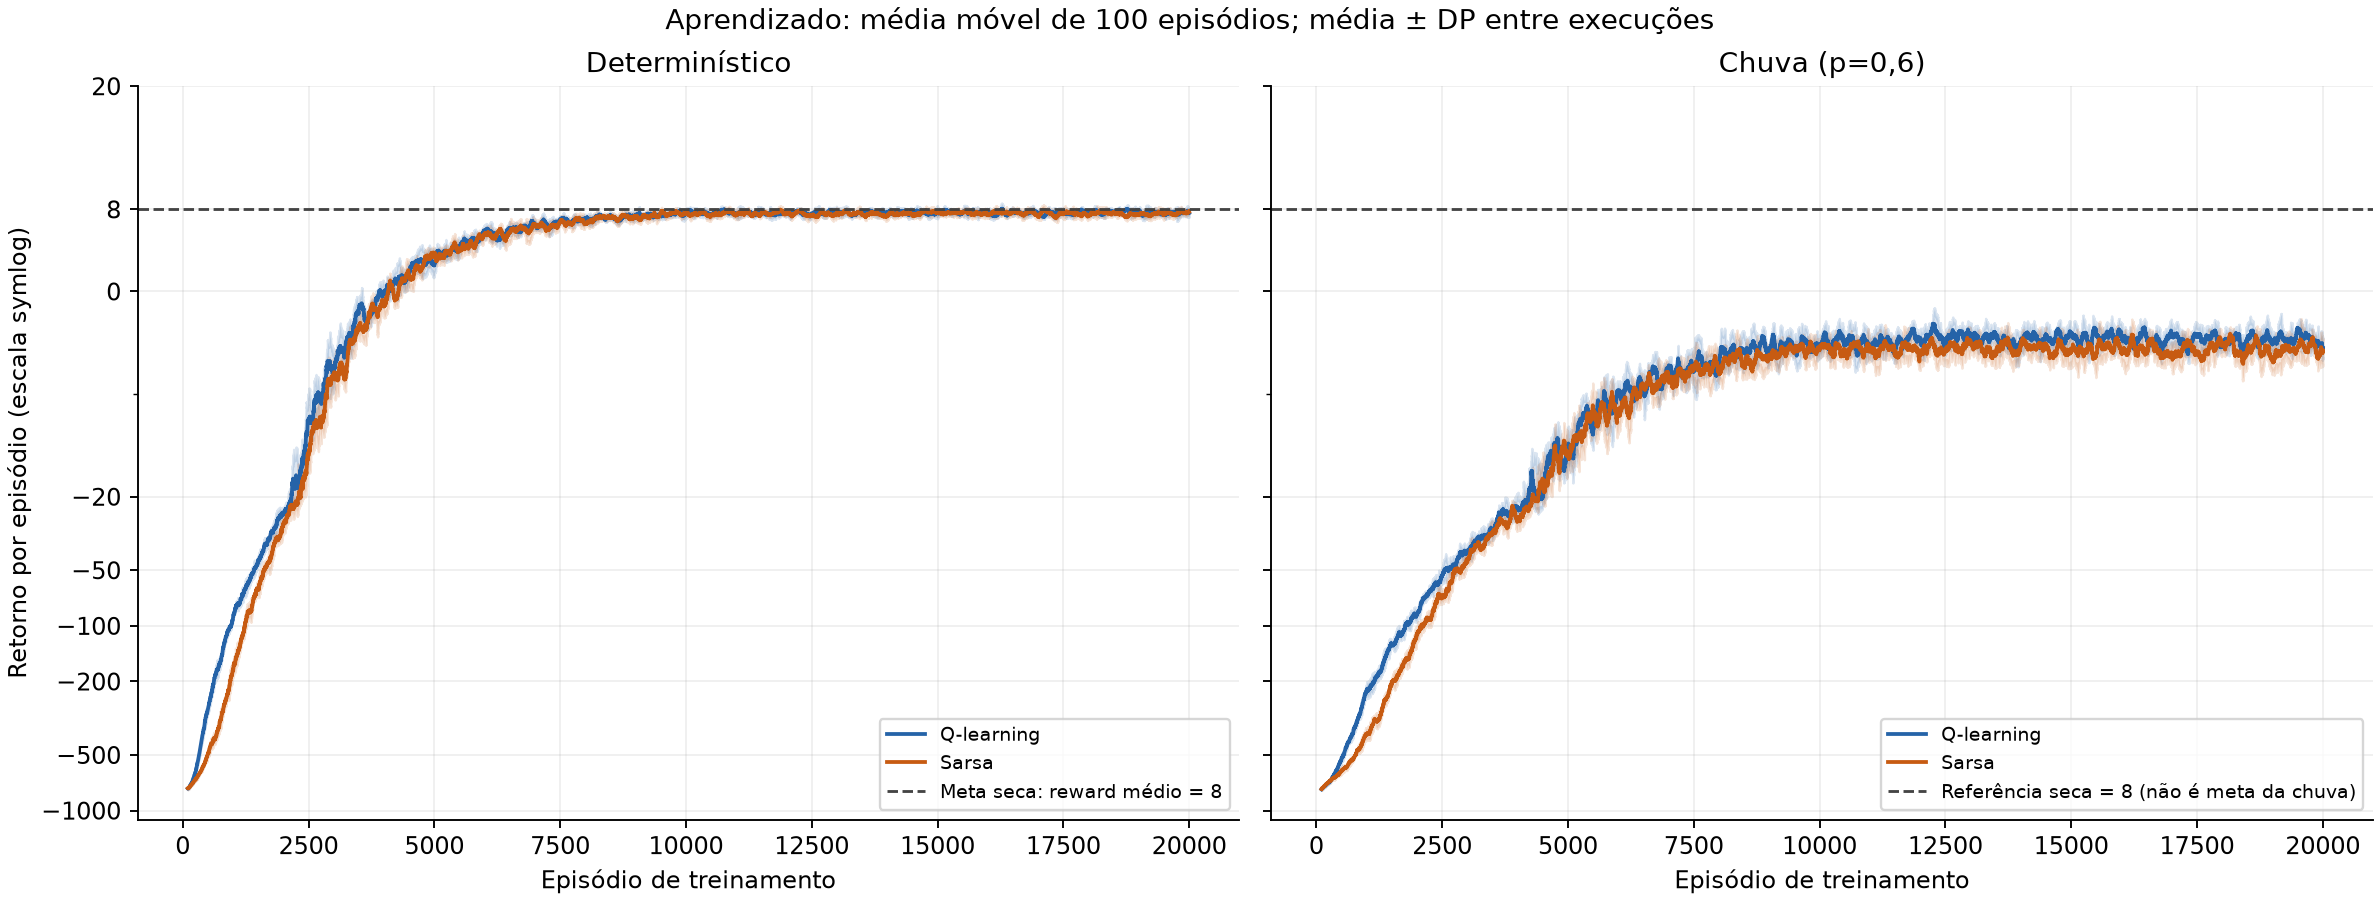

In [5]:
figuras = save_figures(resultados, OUTPUT, CONFIG.smoothing_window)
display(Image(filename=str(figuras["comparacao_aprendizado"])))

As cinco curvas individuais permitem identificar execuções instáveis que
poderiam ficar escondidas pela média. A linha tracejada é a referência seca 8.

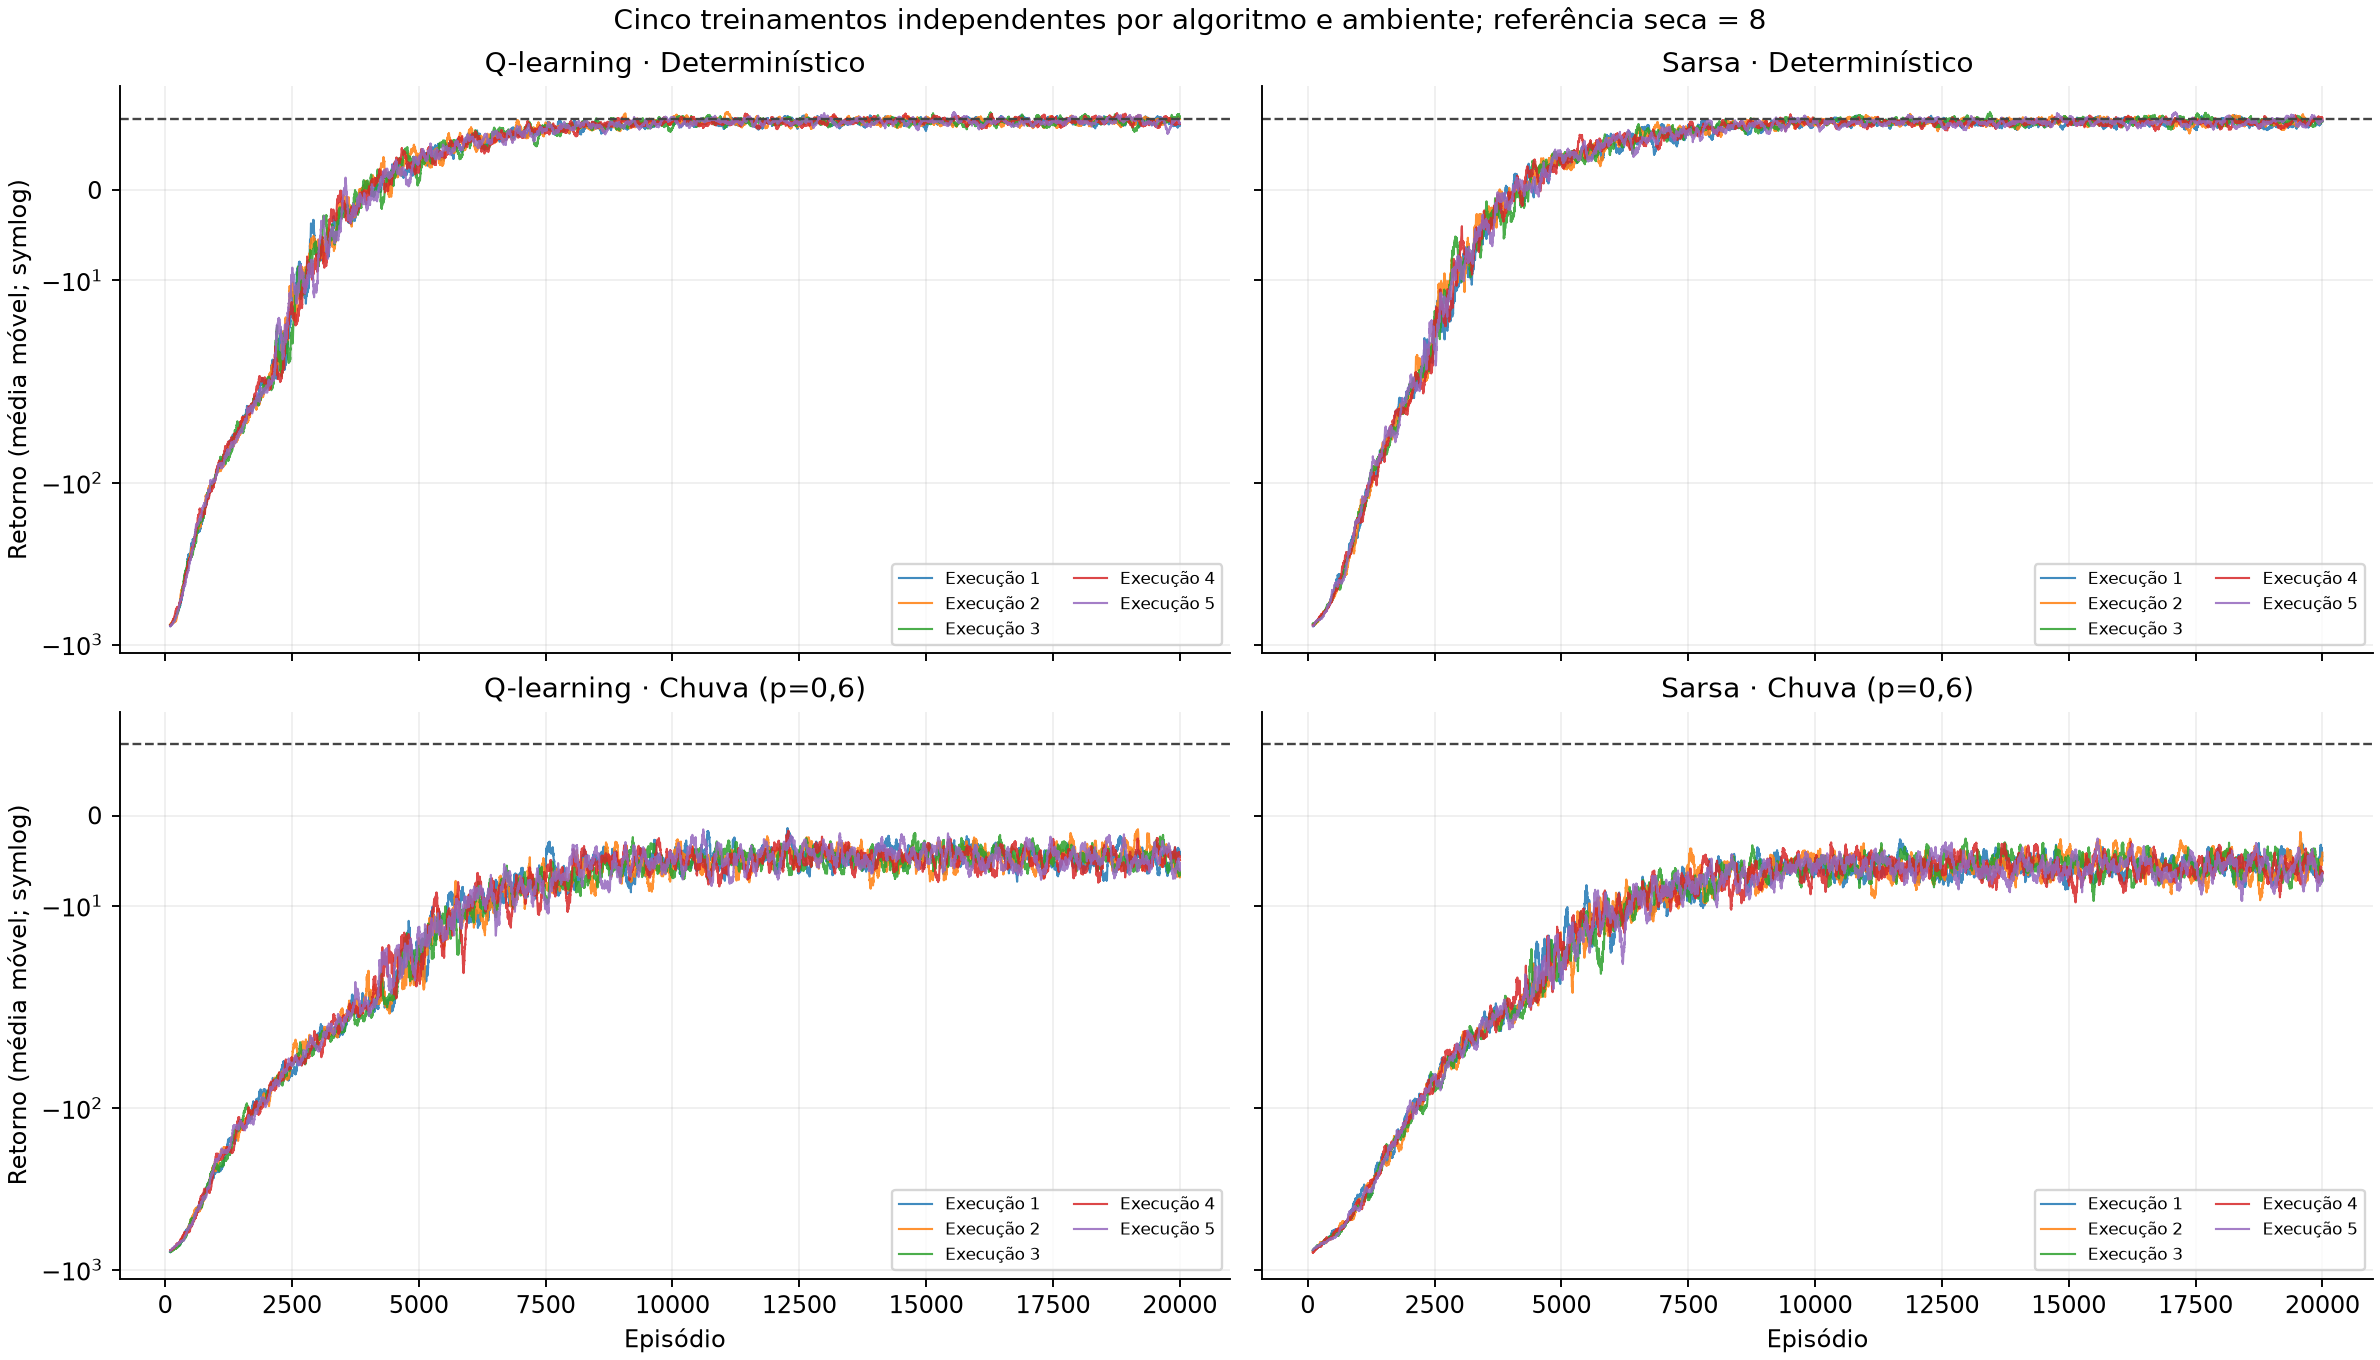

In [6]:
display(Image(filename=str(figuras["cinco_execucoes"])))

O reward de treinamento inclui exploração. Os checkpoints abaixo usam política
gulosa em sementes de **validação**, permitindo verificar a meta sem confundir
exploração com desempenho aprendido. O teste final permanece separado.

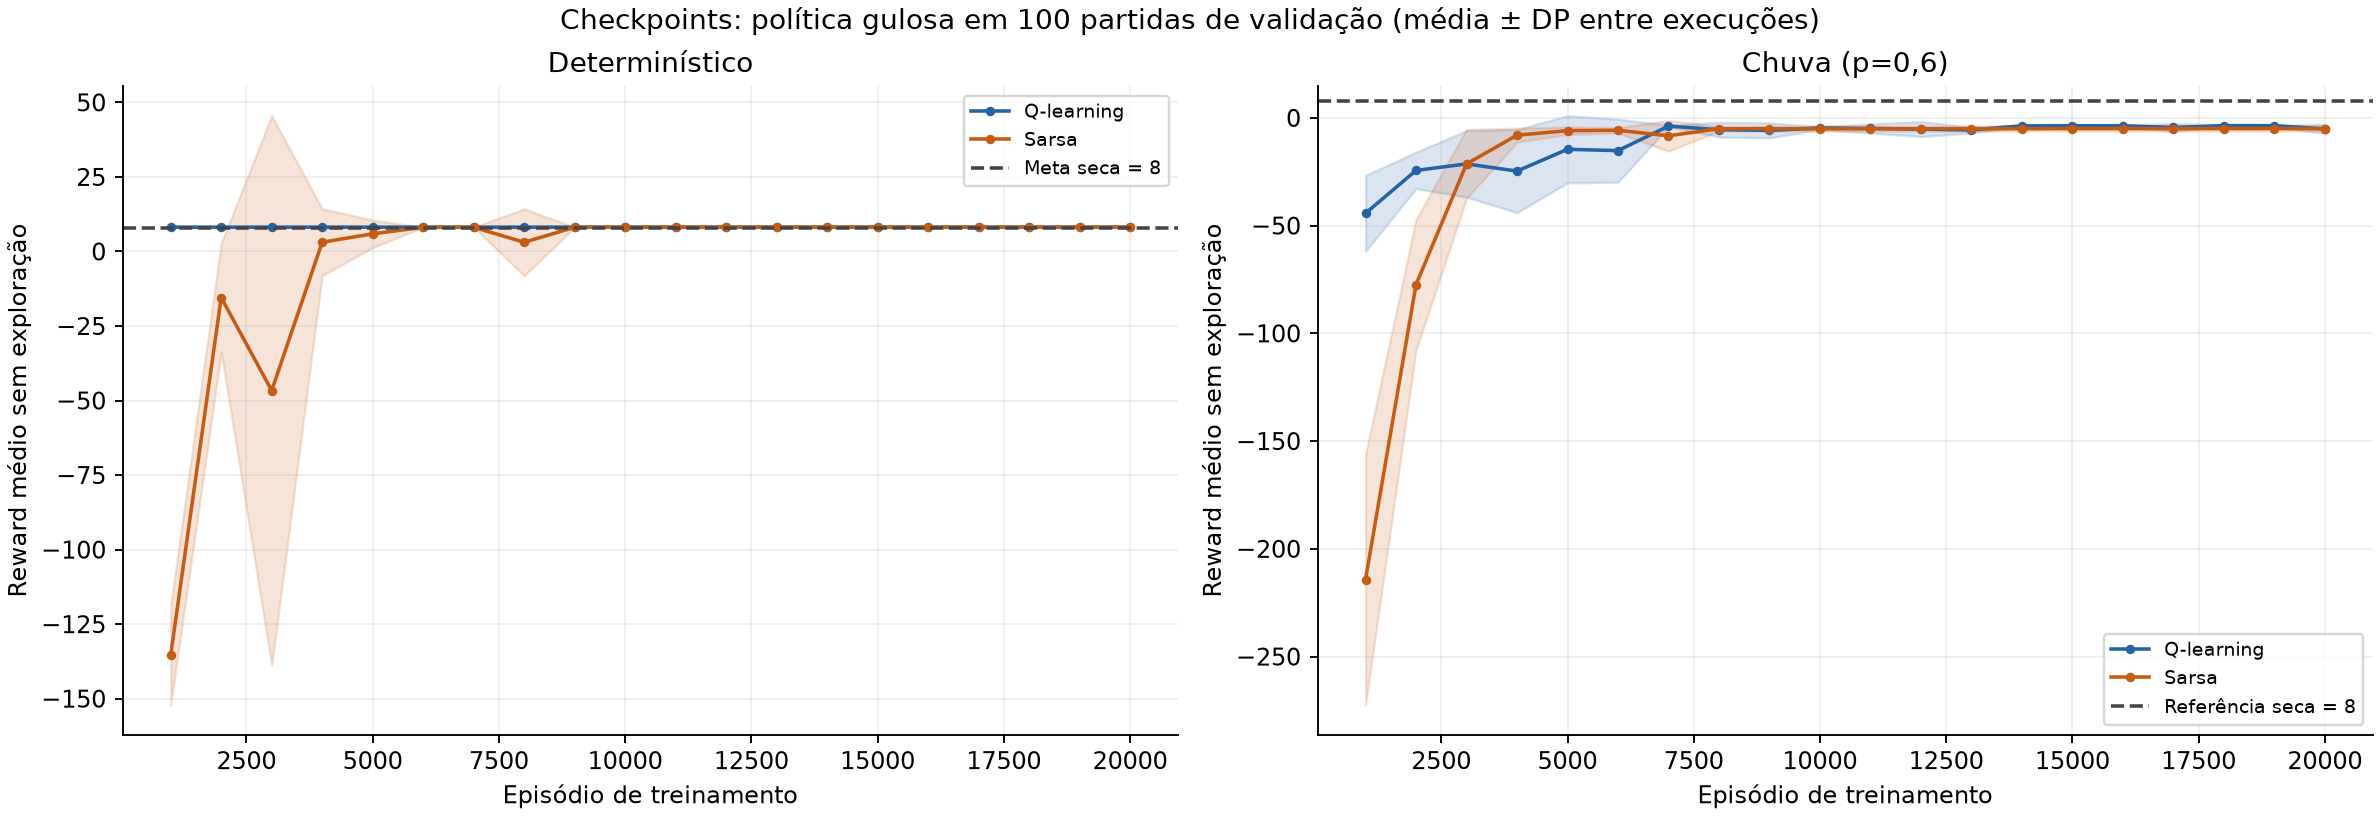

,algoritmo,treino,execucao,reward_medio_treino,reward_primeiros_1000,reward_ultimos_1000,timesteps_treino,primeiro_checkpoint_reward_8,segundos_treino_validacao
0,q_learning,deterministico,1,-14.364,-337.789,7.633,381448,1000.000,7.786
1,q_learning,deterministico,2,-14.358,-335.570,7.833,381510,1000.000,6.810
2,q_learning,deterministico,3,-14.341,-335.204,7.615,380555,1000.000,6.653
3,q_learning,deterministico,4,-13.892,-329.174,7.556,378482,1000.000,5.983
4,q_learning,deterministico,5,-14.556,-338.659,7.615,381493,1000.000,6.091
5,sarsa,deterministico,1,-22.014,-461.167,7.407,431843,4000.000,6.604
6,sarsa,deterministico,2,-22.534,-475.761,7.610,432939,4000.000,6.495
7,sarsa,deterministico,3,-22.065,-464.250,7.744,429053,4000.000,6.495
8,sarsa,deterministico,4,-22.108,-461.766,7.618,431849,3000.000,6.518
9,sarsa,deterministico,5,-21.983,-466.192,7.746,429377,6000.000,6.461


In [7]:
display(Image(filename=str(figuras["checkpoints_gulosos"])))
display(eficiencia)

## 6. Avaliação final — 100 partidas por tabela

Cada passo, inclusive pegar e deixar, conta como um timestep. O desvio padrão
é **amostral (ddof=1)**. A tabela seguinte responde diretamente aos itens 2 e 4
usando a execução 1, escolhida antes de observar os resultados.

As colunas `*_todas` incluem partidas truncadas com o número de passos observados;
são censuradas no limite de 200, não entregas concluídas. As colunas `*_sucesso`
consideram somente entregas efetivamente concluídas. Leia as médias junto da
taxa de sucesso: uma política que falha não pode parecer eficiente só por
encerrar a coleta no limite. O CSV `avaliacoes.csv` registra cada um dos 100 testes.

In [8]:
colunas = ["algoritmo", "treino", "teste", "n_partidas", "taxa_sucesso",
           "n_truncamentos", "timesteps_medios_todas", "timesteps_dp_todas",
           "timesteps_medios_sucesso", "timesteps_dp_sucesso", "reward_medio"]
representante = por_execucao.loc[por_execucao.execucao == 1, colunas]
display(representante)
display(avaliacoes.loc[(avaliacoes.execucao == 1)
                      & (avaliacoes.algoritmo == "q_learning")
                      & (avaliacoes.treino == "deterministico")
                      & (avaliacoes.teste == "deterministico")].head(10))

,algoritmo,treino,teste,n_partidas,taxa_sucesso,n_truncamentos,timesteps_medios_todas,timesteps_dp_todas,timesteps_medios_sucesso,timesteps_dp_sucesso,reward_medio
0,q_learning,deterministico,deterministico,100,1.000,0,13.040,2.470,13.040,2.470,7.960
1,q_learning,deterministico,chuva,100,1.000,0,25.690,8.708,25.690,8.708,-4.690
10,sarsa,deterministico,deterministico,100,1.000,0,13.160,2.639,13.160,2.639,7.840
11,sarsa,deterministico,chuva,100,1.000,0,26.150,8.905,26.150,8.905,-5.150
20,q_learning,chuva,deterministico,100,1.000,0,13.000,2.445,13.000,2.445,8.000
21,q_learning,chuva,chuva,100,1.000,0,24.960,7.670,24.960,7.670,-3.960
30,sarsa,chuva,deterministico,100,1.000,0,13.440,2.713,13.440,2.713,7.560
31,sarsa,chuva,chuva,100,1.000,0,25.690,8.340,25.690,8.340,-4.690


,episodio,seed_avaliacao,timesteps,reward,sucesso,truncado,acoes_ilegais,algoritmo,treino,teste,execucao,seed_treino
0,1,1000000,16,5.000,True,False,0,q_learning,deterministico,deterministico,1,2026
1,2,1000001,12,9.000,True,False,0,q_learning,deterministico,deterministico,1,2026
2,3,1000002,12,9.000,True,False,0,q_learning,deterministico,deterministico,1,2026
3,4,1000003,15,6.000,True,False,0,q_learning,deterministico,deterministico,1,2026
4,5,1000004,15,6.000,True,False,0,q_learning,deterministico,deterministico,1,2026
5,6,1000005,17,4.000,True,False,0,q_learning,deterministico,deterministico,1,2026
6,7,1000006,8,13.000,True,False,0,q_learning,deterministico,deterministico,1,2026
7,8,1000007,14,7.000,True,False,0,q_learning,deterministico,deterministico,1,2026
8,9,1000008,17,4.000,True,False,0,q_learning,deterministico,deterministico,1,2026
9,10,1000009,13,8.000,True,False,0,q_learning,deterministico,deterministico,1,2026


Para verificar a consistência entre sementes, apresentamos também os cinco
blocos de 100 partidas separadamente e o resumo agrupado (500 partidas por
condição). Os cinco blocos compartilham as sementes de teste; não representam
500 treinamentos independentes. O gráfico usa média ± DP dos timesteps das partidas.

,execucao,algoritmo,treino,teste,n_partidas,taxa_sucesso,n_truncamentos,timesteps_medios_todas,timesteps_dp_todas,timesteps_medios_sucesso,timesteps_dp_sucesso,reward_medio
0,1,q_learning,deterministico,deterministico,100,1.000,0,13.040,2.470,13.040,2.470,7.960
1,1,q_learning,deterministico,chuva,100,1.000,0,25.690,8.708,25.690,8.708,-4.690
2,2,q_learning,deterministico,deterministico,100,1.000,0,13.000,2.445,13.000,2.445,8.000
3,2,q_learning,deterministico,chuva,100,1.000,0,25.340,8.509,25.340,8.509,-4.340
4,3,q_learning,deterministico,deterministico,100,1.000,0,13.000,2.445,13.000,2.445,8.000
5,3,q_learning,deterministico,chuva,100,1.000,0,25.880,8.420,25.880,8.420,-4.880
6,4,q_learning,deterministico,deterministico,100,1.000,0,13.000,2.445,13.000,2.445,8.000
7,4,q_learning,deterministico,chuva,100,1.000,0,25.570,8.737,25.570,8.737,-4.570
8,5,q_learning,deterministico,deterministico,100,1.000,0,13.020,2.454,13.020,2.454,7.980
9,5,q_learning,deterministico,chuva,100,1.000,0,25.690,8.573,25.690,8.573,-4.690


,algoritmo,treino,teste,n_partidas,taxa_sucesso,n_truncamentos,timesteps_medios_todas,timesteps_dp_todas,timesteps_medios_sucesso,timesteps_dp_sucesso,reward_medio
0,q_learning,deterministico,deterministico,500,1.000,0,13.012,2.442,13.012,2.442,7.988
1,q_learning,deterministico,chuva,500,1.000,0,25.634,8.557,25.634,8.557,-4.634
2,sarsa,deterministico,deterministico,500,1.000,0,13.084,2.507,13.084,2.507,7.916
3,sarsa,deterministico,chuva,500,1.000,0,26.308,9.189,26.308,9.189,-5.308
4,q_learning,chuva,deterministico,500,1.000,0,13.036,2.447,13.036,2.447,7.964
5,q_learning,chuva,chuva,500,1.000,0,25.130,8.276,25.130,8.276,-4.130
6,sarsa,chuva,deterministico,500,0.968,16,19.198,33.010,13.221,2.665,1.130
7,sarsa,chuva,chuva,500,1.000,0,26.100,9.258,26.100,9.258,-5.100


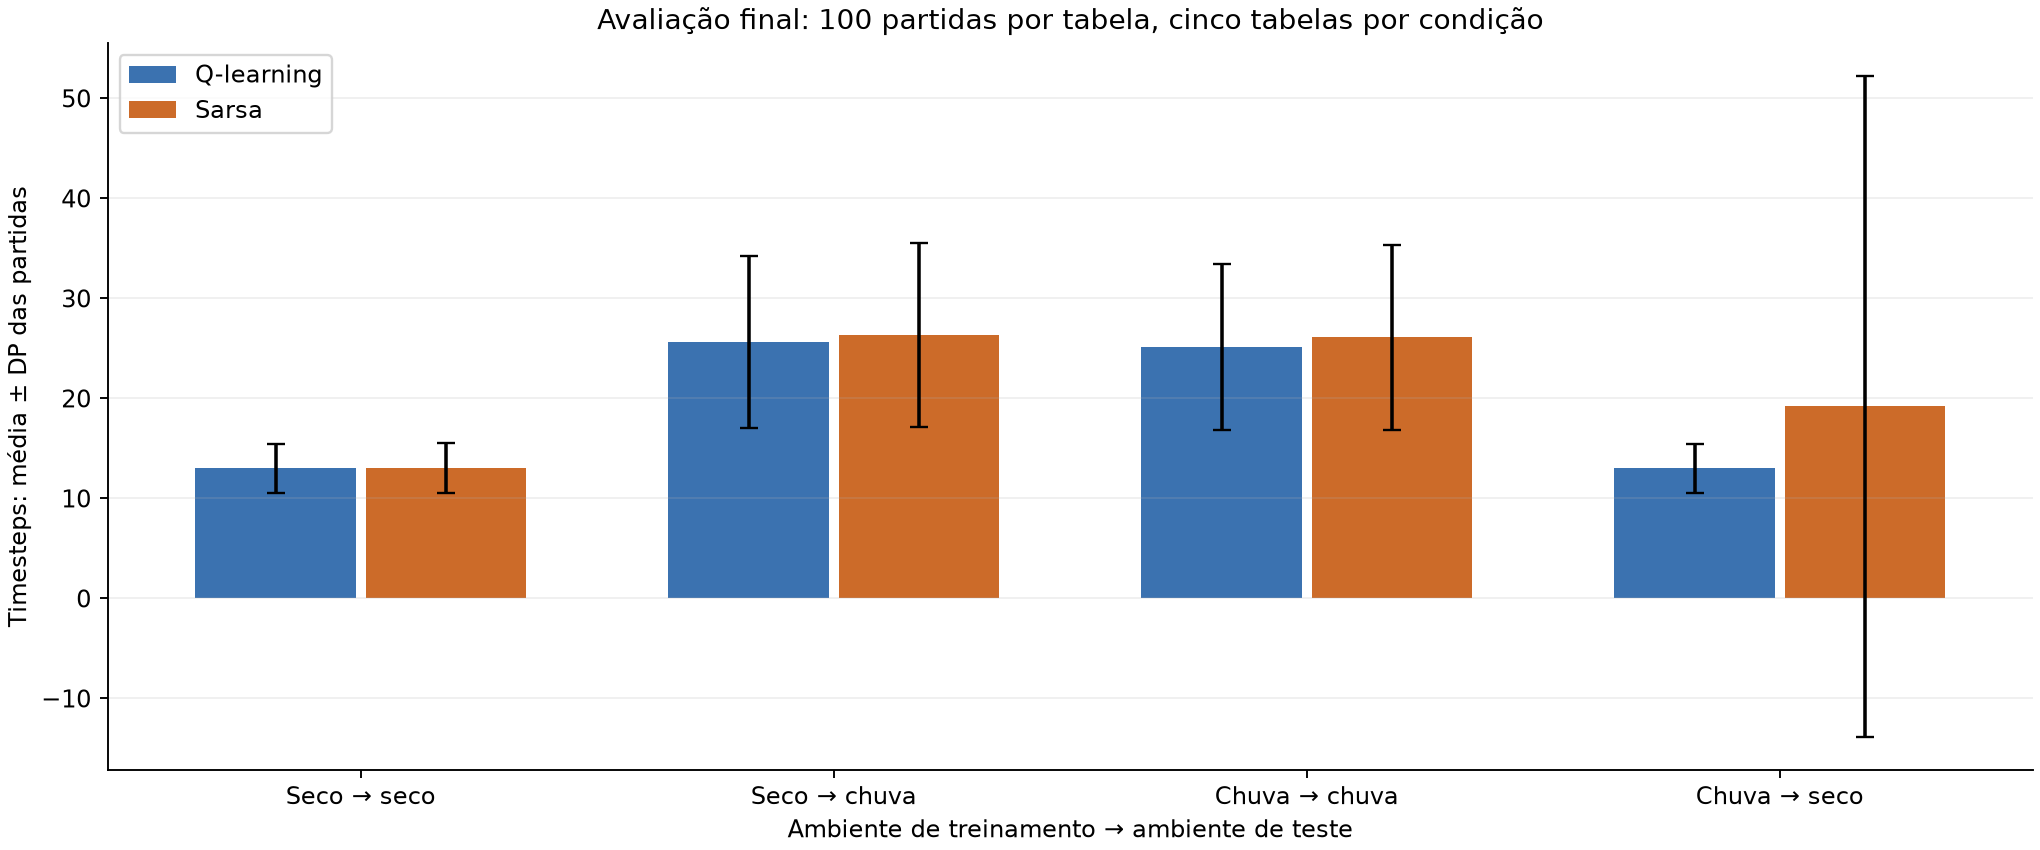

In [9]:
display(por_execucao[["execucao"] + colunas])
display(resumo[colunas])
display(Image(filename=str(figuras["desempenho_final"])))

## 7. Impacto da chuva e do retreinamento

**Transferência:** compara seco → chuva com seco → seco, mantendo a mesma tabela.
**Retreinamento:** compara chuva → chuva com seco → chuva. Valores negativos nas
diferenças de timesteps indicam menor custo na segunda condição comparada.
As comparações são calculadas por tabela/execução para preservar os cinco blocos.

In [10]:
comparacoes = []
for (algoritmo, execucao), grupo in por_execucao.groupby(["algoritmo", "execucao"]):
    valores = grupo.set_index(["treino", "teste"])
    seco = valores.loc[("deterministico", "deterministico")]
    transferencia = valores.loc[("deterministico", "chuva")]
    retreinado = valores.loc[("chuva", "chuva")]
    comparacoes.append({
        "algoritmo": algoritmo, "execucao": execucao,
        "delta_chuva_sem_retreino": transferencia.timesteps_medios_todas - seco.timesteps_medios_todas,
        "delta_retreinar_na_chuva": retreinado.timesteps_medios_todas - transferencia.timesteps_medios_todas,
        "delta_chuva_treinada_vs_seco": retreinado.timesteps_medios_todas - seco.timesteps_medios_todas,
    })
comparacoes = pd.DataFrame(comparacoes)
comparacoes.to_csv(OUTPUT / "comparacoes.csv", index=False)
display(comparacoes)
display(comparacoes.groupby("algoritmo")[list(comparacoes.columns[2:])].agg(["mean", "std"]))

,algoritmo,execucao,delta_chuva_sem_retreino,delta_retreinar_na_chuva,delta_chuva_treinada_vs_seco
0,q_learning,1,12.650,-0.730,11.920
1,q_learning,2,12.340,-0.100,12.240
2,q_learning,3,12.880,-0.690,12.190
3,q_learning,4,12.570,-0.240,12.330
4,q_learning,5,12.670,-0.760,11.910
5,sarsa,1,12.990,-0.460,12.530
6,sarsa,2,13.400,-0.950,12.450
7,sarsa,3,13.460,-1.460,12.000
8,sarsa,4,13.450,1.010,14.460
9,sarsa,5,12.820,0.820,13.640


delta_chuva_sem_retreino       delta_retreinar_na_chuva        \
                               mean   std                     mean   std   
algoritmo                                                                  
q_learning                   12.622 0.195                   -0.504 0.310   
sarsa                        13.224 0.298                   -0.208 1.086   

           delta_chuva_treinada_vs_seco        
                                   mean   std  
algoritmo                                      
q_learning                       12.118 0.192  
sarsa                            13.016 1.008

## 8. Discussão dos resultados e conclusões

O texto seguinte é gerado a partir dos valores medidos, incluindo diferenças,
dispersões e alcance da meta. Assim, executar novamente com outra configuração
não mantém conclusões numéricas desatualizadas.

In [11]:
display(Markdown(discussion(resultados)))

### Itens 1–3: aprendizado e desempenho no ambiente determinístico


**Q-learning:** 13.01 ± 2.44 timesteps, reward médio 7.99 e sucesso em 100.0% das partidas. O retorno médio de treinamento foi -14.30, e nos últimos 1.000 episódios foi 7.65. A meta de validação 8 foi atingida por 5/5 execuções, com primeiro checkpoint em média no episódio 1000.

**Sarsa:** 13.08 ± 2.51 timesteps, reward médio 7.92 e sucesso em 100.0% das partidas. O retorno médio de treinamento foi -22.14, e nos últimos 1.000 episódios foi 7.62. A meta de validação 8 foi atingida por 5/5 execuções, com primeiro checkpoint em média no episódio 4200.

Quanto ao custo de aprender no seco, Q-learning − Sarsa = +7.84 unidades de reward médio ao longo do treino (valor positivo favorece Q-learning). Os checkpoints e os retornos iniciais ajudam a identificar diferenças de velocidade que podem desaparecer no teste final. Um orçamento comum permite acompanhar também a estabilização do cenário chuvoso, mesmo que um método resolva o seco antes.

A diferença observada Sarsa − Q-learning no teste seco é +0.07 timesteps. Ela descreve esta amostra; não demonstra superioridade estatística. O retorno médio durante todo o treinamento mede o custo da exploração; os checkpoints medem a qualidade da política gulosa. O primeiro cruzamento da meta pode ser transitório e tem resolução igual ao intervalo dos checkpoints, portanto não é uma prova de convergência.

A meta é verificada nas sementes de validação. Uma média de teste ligeiramente abaixo de 8 pode coexistir com checkpoints acima de 8: o teste tem outros estados iniciais e apenas 100 partidas por tabela, além de possíveis diferenças residuais da política. A meta não é uma garantia para qualquer amostra de estados.

### Item 4: transferência da política seca para a chuva


**Q-learning:** sem retreinar, a tabela seca passou de 13.01 ± 2.44 para 25.63 ± 8.56 timesteps na chuva (variação de +12.62); sucesso 100.0%, reward médio -4.63.

**Sarsa:** sem retreinar, a tabela seca passou de 13.08 ± 2.51 para 26.31 ± 9.19 timesteps na chuva (variação de +13.22); sucesso 100.0%, reward médio -5.31.

A política consulta o estado novamente depois de cada passo, podendo corrigir desvios. Isso permite alguma transferência sem novo treinamento, mas caminhos curtos no seco podem ter maior custo esperado na chuva. Aqui p=0,6 significa 60% de movimento na direção solicitada e 20% para cada lateral. Paredes podem impedir movimentos sorteados, produzindo passos sem deslocamento. Pegar e deixar o passageiro continuam determinísticos.

### Item 5: treinamento no ambiente não determinístico


**Q-learning treinado na chuva:** 25.13 ± 8.28 timesteps, sucesso 100.0% e reward médio -4.13. Retreinar reduziu o custo médio em 0.50 timesteps em relação à transferência da tabela seca. Em relação ao treino/teste secos, a diferença é +12.12 timesteps. O retorno médio ao longo do treino na chuva foi -40.84 e nos últimos 1.000 episódios, -4.69.

**Sarsa treinado na chuva:** 26.10 ± 9.26 timesteps, sucesso 100.0% e reward médio -5.10. Retreinar reduziu o custo médio em 0.21 timesteps em relação à transferência da tabela seca. Em relação ao treino/teste secos, a diferença é +13.02 timesteps. O retorno médio ao longo do treino na chuva foi -50.83 e nos últimos 1.000 episódios, -5.60.

Na avaliação após treino na chuva, Sarsa − Q-learning = +0.97 timesteps. Durante o aprendizado na chuva, Q-learning − Sarsa = +9.99 unidades de reward médio. Q-learning é off-policy: seu alvo usa a melhor próxima ação, mesmo que o comportamento ainda explore. Sarsa é on-policy: usa a próxima ação realmente escolhida pela política epsilon-greedy e incorpora seu custo de exploração. Conforme epsilon diminui, os alvos ficam mais próximos. Sarsa não é necessariamente superior na chuva: ambos estimam retornos esperados a partir de transições estocásticas; Q-learning também considera essa aleatoriedade, apesar de maximizar sobre ações.

### Diagnóstico adicional: política da chuva aplicada no seco


**Q-learning (chuva → seco):** 13.04 ± 2.45 timesteps observados, sucesso 100.0% e 0 truncamentos. Entre as partidas concluídas, a média foi 13.04 timesteps.

**Sarsa (chuva → seco):** 19.20 ± 33.01 timesteps observados, sucesso 96.8% e 16 truncamentos. Entre as partidas concluídas, a média foi 13.22 timesteps.

Transferência não é simétrica. Uma ação cujo movimento pretendido é bloqueado pode ainda provocar deslocamento lateral na chuva; no seco, essa mesma ação pode manter o táxi parado indefinidamente. Isso oferece uma explicação possível para falhas de transferência reversa, junto de valores ainda imprecisos após treinamento finito. Identificar a causa de cada falha exigiria inspecionar suas trajetórias; a taxa de sucesso, por si só, não distingue essas causas.

### Variabilidade e limites


Q-learning / Determinístico: o DP entre as médias das 5 tabelas é 0.018 timesteps.

Q-learning / Chuva (p=0,6): o DP entre as médias das 5 tabelas é 0.176 timesteps.

Sarsa / Determinístico: o DP entre as médias das 5 tabelas é 0.048 timesteps.

Sarsa / Chuva (p=0,6): o DP entre as médias das 5 tabelas é 1.008 timesteps.

O DP das partidas mistura a variação dos estados iniciais, das transições na chuva e das tabelas. O DP entre médias das tabelas descreve separadamente a sensibilidade ao treinamento. As 500 partidas agrupadas por condição são cinco blocos de 100, com as mesmas sementes de teste entre tabelas; não são 500 réplicas independentes do aprendizado. As sementes iguais tornam os estados iniciais comparáveis, mas políticas diferentes produzem trajetórias distintas, e não garantem os mesmos desvios em cada estado. Falhas são censuradas no limite de passos: por isso as tabelas informam taxa de sucesso e médias de timesteps tanto de todas as partidas quanto somente das concluídas. Hiperparâmetros fixados antes dos testes; nenhuma tabela foi selecionada pelo resultado do teste. A execução 1 é a representante predefinida.

### Conclusões


Os experimentos separam três efeitos: aprender com exploração, executar uma política gulosa e transferir essa política para outra dinâmica. A chuva adiciona desvios e passos sem progresso, alterando o custo esperado das rotas e a variabilidade dos retornos. As medições acima mostram se o retreinamento compensou esse efeito neste orçamento de episódios. Retorno negativo na chuva não implica necessariamente falha: sem ações ilegais, uma entrega bem-sucedida em T passos tem retorno 21 − T. A meta 8 do ambiente seco não é uma exigência para a chuva. Os resultados são evidência empírica de políticas aprendidas; treinamento finito, taxa de aprendizado decrescente e epsilon mínimo positivo não certificam a política ótima nem satisfazem automaticamente todas as hipóteses de convergência assintótica.

## 9. Reutilização da Q-table e arquivos de entrega

A função abaixo carrega uma tabela e executa uma partida com renderização textual.
Para visualizar uma janela, instale `pygame-ce` e use `render_mode="human"`.
Essa visualização é opcional e não interfere nos experimentos.

In [12]:
tabela = OUTPUT / "q_tables" / "q_learning_deterministico_execucao_1.npy"
print("Exemplo de uso (opcional):")
print(f"demonstrate({str(tabela)!r}, scenario='chuva', render_mode='ansi')")
# Descomente para acompanhar uma partida:
# demonstrate(tabela, scenario="chuva", render_mode="ansi")
display(pd.DataFrame([
    {"Arquivo": path.name, "Tamanho (KB)": round(path.stat().st_size / 1024, 1)}
    for path in sorted(OUTPUT.glob("*.csv"))
]))
print((OUTPUT / "metadados.json").read_text(encoding="utf-8"))

Exemplo de uso (opcional):
demonstrate('resultados\\q_tables\\q_learning_deterministico_execucao_1.npy', scenario='chuva', render_mode='ansi')


,Arquivo,Tamanho (KB)
0,avaliacoes.csv,269.600
1,checkpoints.csv,18.900
2,comparacoes.csv,0.700
3,eficiencia_aprendizado.csv,1.600
4,resumo_avaliacoes.csv,1.100
5,resumo_por_execucao.csv,4.900
6,treinamento.csv,25317.500


{
  "config": {
    "episodes": 20000,
    "runs": 5,
    "evaluation_episodes": 100,
    "alpha": 0.6,
    "alpha_decay": 0.01,
    "alpha_power": 0.6,
    "gamma": 0.99,
    "epsilon_start": 1.0,
    "epsilon_min": 0.005,
    "epsilon_decay": 0.9995,
    "max_steps": 200,
    "rainy_probability": 0.6,
    "seed": 2026,
    "evaluation_seed": 1000000,
    "validation_seed": 2000000,
    "checkpoint_every": 1000,
    "validation_episodes": 100,
    "smoothing_window": 100
  },
  "gymnasium": "1.3.0",
  "numpy": "2.5.4",
  "pandas": "2.3.3",
  "python": "3.13.13",
  "platform": "Windows-11-10.0.26200-SP0",
  "desvio_padrao": "amostral (ddof=1)",
  "politica_teste": "gulosa, epsilon=0, empates por menor índice",
  "representante": "execução 1, definida antes do treinamento",
  "mascara_acoes": false,
  "reward_threshold_deterministico": 8
}
